## testing

In [101]:
import warnings
warnings.filterwarnings('ignore')

In [102]:
import numpy as np
import os
import xarray as xr
import xcdat as xc
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm as BM
import pandas as pd
import matplotlib as mpl
import matplotlib.ticker as mticker
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

In [103]:
from scipy import stats

In [104]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 12
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 2.0
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [105]:
# plt.style.use('dark_background')

### Functions needed for the analysis

In [106]:
import matplotlib as m
from matplotlib.colors import BoundaryNorm as BM
import matplotlib.patches as mpatches

def plot_background(ax):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=True,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    return ax


def plot_maps(x, y, z, titles, labels, cmap, levels, cbar_label = 'Precip', pval = [], nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False):
    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=True, subplot_kw={'projection':ccrs.Robinson(central_longitude=180)})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax)
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        axlist[i].set_title(titles[i])
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='////', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':12})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
        
    norm = BM(levels, 256, extend='both')
    fig.colorbar(m.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                orientation = 'horizontal', shrink=0.4, aspect = 20, pad = 0.05, label = cbar_label)

In [107]:
from functions import preproc_funcs as funcs

In [108]:
from functions import xr_lowess

### load data

In [109]:
precip_obs = xr.open_mfdataset('/g/data/ob22/as8561/data/obs_local/gpcc_v2020/precip.mon.total.1x1.v2020.nc').precip.load()
precip_obs

<xarray.DataArray 'precip' (time: 1548, lat: 180, lon: 360)>
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 355.5 356.5 357.5 358.5 359.5
  * time     (time) datetime64[ns] 1891-01-01 1891-02-01 ... 2019-12-01
Attributes:
    long_name:     GPCC Monthly total of precipitation
    statistic:     Total
    valid_range:   [   0. 8000.]
    parent_stat:   Observations
    var_desc:      Precipitation
    units:         mm
    level:         Surface
    dataset:       GPCC Precipitation 1.0degree V2020 Full Reanalysis
    actual_range:  [   0.   4830.39]

In [110]:
sst_obs = xc.open_dataset('/g/data/ob22/as8561/data/obs_local/sst_obs.nc', lon_orient=(0,360)).sst
sst_obs = sst_obs.rename(dict(latitude='lat', longitude='lon'))
sst_obs

<xarray.DataArray 'sst' (time: 1837, lat: 180, lon: 361)>
array([[[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        ...,
...
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. ,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8, -1000. , ...,    -1.8,    -1.8,    -1.8],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]],

       [[-1000. , -1000. , -1000. , ..., -1000. , -1000. , -1000. ],
        [   -1.8,    -1.8,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        [-1000. , -1000. ,    -1.8, ...,    -1.8,    -1.8,    -1.8],
        ...,
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan],
        [    nan,     nan,     nan, ...,     nan,     nan,     nan]]],
      dtype=float32)
Coordinates:
  * time     (time) object 1870-01-16 11:59:59.505615 ... 2023-01-16 12:00:00
  * lat      (lat) float32 89.5 88.5 87.5 86.5 85.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5 359.5
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      sst
    units:          C
    cell_methods:   time: lat: lon: mean

In [112]:
sst_obs_anom = funcs.calc_anom(sst_obs, sst_obs.sel(time = slice('1960', '1990'))).resample(time='AS-JUN').mean('time')
weights_sst_obs = np.cos(np.deg2rad(sst_obs.lat))
nino34_obs = funcs.detrend_separate_check(sst_obs_anom.sel(lat=slice(5,-5), lon = slice(-170+360, -120+360)).weighted(weights_sst_obs).mean(('lat', 'lon')), period=15, dim='time')


In [113]:
import seaborn as sns

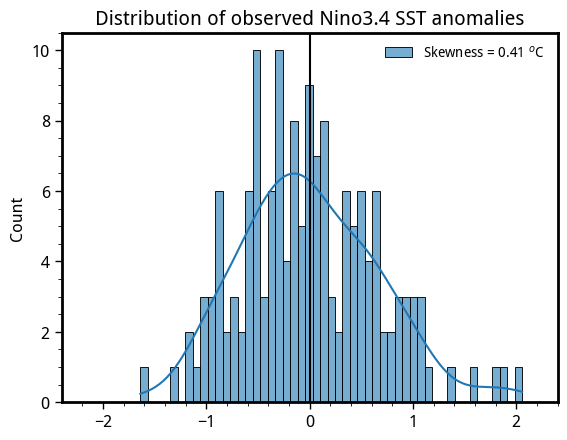

In [114]:
sns.histplot(nino34_obs, bins=51, kde=True, alpha=0.6, color='tab:blue', label=f'Skewness = {np.round(stats.skew(nino34_obs), 3)} $^o$C')
plt.axvline(0.0, color='k', ls='-')
plt.xlim(-2.4, 2.4)
plt.minorticks_on()
plt.title('Distribution of observed Nino3.4 SST anomalies')
plt.legend(frameon=False, fontsize=10)

[Text(1, 0, 'strong-LN'),
 Text(2, 0, 'LN'),
 Text(3, 0, 'NEUT'),
 Text(4, 0, 'EN'),
 Text(5, 0, 'strong-EN')]

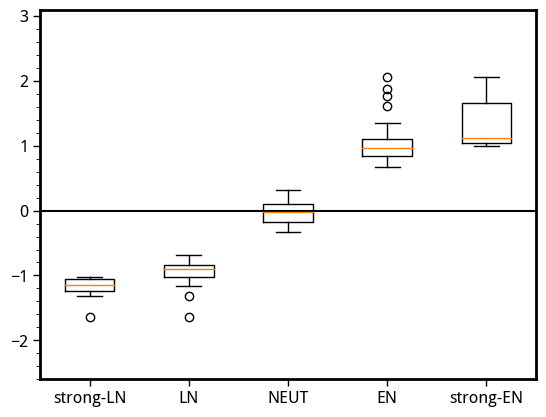

In [115]:
thres = nino34_obs.std('time')
plt.boxplot([nino34_obs.where(nino34_obs < -1.5*thres, drop=True),
             nino34_obs.where(nino34_obs < -thres, drop=True),
             nino34_obs.where((nino34_obs > -0.5*thres) & (nino34_obs < 0.5*thres), drop=True),
             nino34_obs.where(nino34_obs > thres, drop=True),
             nino34_obs.where(nino34_obs > 1.5*thres, drop=True)])


plt.ylim(-2.6, 3.1)
plt.axhline(0.0, color='k', ls='-')
plt.minorticks_on()
plt.tick_params(axis='x', which='minor', bottom=False)
plt.gca().set_xticklabels(['strong-LN', 'LN', 'NEUT', 'EN', 'strong-EN'])

In [116]:
import regionmask

In [117]:
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(precip_obs)
ar6_mask = regionmask.defined_regions.ar6.land.mask_3D(precip_obs.where(land_mask))

In [119]:
precip_obs_anom = funcs.calc_anom(precip_obs, precip_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time')

In [122]:
eaus_anom = precip_obs_anom.where(ar6_mask.isel(region=41)).mean(('lat', 'lon'))

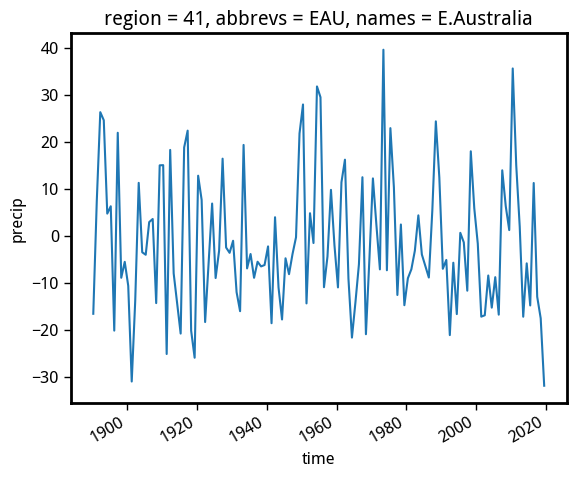

In [123]:
eaus_anom.plot()

In [155]:
eaus_det = funcs.detrend_separate_check(eaus_anom, dim='time', period=15)
eaus_std = eaus_det/eaus_det.std('time')

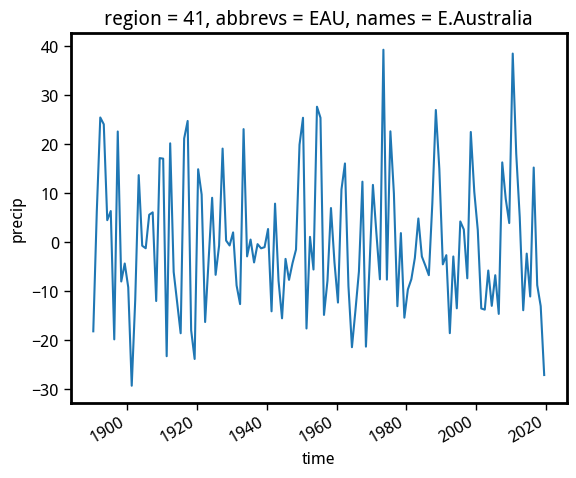

In [156]:
eaus_det.plot()

In [157]:
def calc_tele(precip: xr.DataArray, nino34: xr.DataArray, start_year: int, end_year: int):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    duration = end_year - start_year
    res = stats.linregress(nino34.sel(time=slice(str(start_year), str(end_year))), precip.sel(time=slice(str(start_year), str(end_year))))
    return res.slope, res.pvalue, duration


def get_all_tele(precip: xr.DataArray, nino34: xr.DataArray, initial_dur: int = 10):
    if not isinstance(precip, xr.DataArray) or not isinstance(nino34, xr.DataArray):
        raise TypeError("'xr.DataArray' input is required, not the %s" % (type(precip)))
    start_years = np.arange(1900, 2002, 2)
    end_years = np.arange(1900, 2002, 2)
    slope = np.empty((len(start_years), len(end_years)))
    pval = np.empty((len(start_years), len(end_years)))
    duration = np.empty((len(start_years), len(end_years)))
    for i in range(len(start_years)):
        for j in range(len(end_years)):
            if end_years[j] < start_years[i] + initial_dur:
                slope[i, j], pval[i, j], duration[i, j] = np.NaN, np.NaN, np.NaN
            else:
                slope[i, j], pval[i, j], duration[i, j] = calc_tele(precip, nino34, start_years[i], end_years[j])
        # print(f"Completed {start_years[i]}", end='\r')
    return start_years, end_years, slope, pval, duration

In [158]:
calc_tele(eaus_std, nino34_obs, start_year=1900, end_year=2000)

(-0.8302614325726113, 1.0003568357592924e-09, 100)

In [159]:
sy, ey, sl, p, dur = get_all_tele(eaus_std, nino34_obs, initial_dur=30)

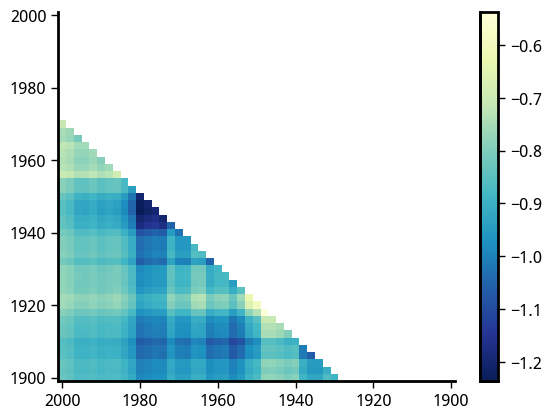

In [160]:
x, y = np.meshgrid(ey, sy)
cf=plt.pcolormesh(ey, sy, sl, cmap='YlGnBu_r')
plt.colorbar()
sns.despine()
# plt.gca().invert_yaxis()
plt.gca().invert_xaxis()

#### next steps - do the same for one large ensemble and the suite of CMIP6 models

In [252]:
access_ts_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_ts.nc').ts.sel(time = slice('1850', '2100'))
access_ts_ssp5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5o_ts.nc').ts.sel(time = slice('1850', '2100'))

In [253]:
access_pr_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp5 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp3_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp3 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp2_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp2 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp1 = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp1_pr.nc').pr.sel(time = slice('1850', '2100'))
access_pr_ssp5o = xr.open_dataset('/g/data/ob22/as8561/data/enso_trans_stable/sst_grad_res/lens/ACCESS-ESM1-5_ssp5o_pr.nc').pr.sel(time = slice('1850', '2100'))

In [254]:
access_pr_ssp5['model'] = access_ts_ssp5['model']
access_pr_ssp3['model'] = access_ts_ssp3['model']
access_pr_ssp2['model'] = access_ts_ssp2['model']
access_pr_ssp1['model'] = access_ts_ssp1['model']
access_pr_ssp5o['model'] = access_ts_ssp5o['model']

In [255]:
weights_access = np.cos(np.deg2rad(access_ts_ssp5.lat))
nino34_access_ssp5 = funcs.detrend_separate_check(access_ts_ssp5.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp3 = funcs.detrend_separate_check(access_ts_ssp3.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp2 = funcs.detrend_separate_check(access_ts_ssp2.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp1 = funcs.detrend_separate_check(access_ts_ssp1.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')
nino34_access_ssp5o = funcs.detrend_separate_check(access_ts_ssp5o.sel(lat = slice(-5,5), lon=slice(-170+360, -120+360)).weighted(weights_access).mean(('lat', 'lon')), period=15, dim='time')

In [236]:
land_mask_access = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(access_pr_ssp5)
ar6_mask_access = regionmask.defined_regions.ar6.land.mask_3D(access_pr_ssp5.where(land_mask_access))

eaus_access_ssp5_anom = access_pr_ssp5.where(ar6_mask_access.isel(region=41)).mean(('lat', 'lon'))
eaus_access_ssp5_anom = access_pr_ssp5.where(ar6_mask_access.isel(region=41)).mean(('lat', 'lon'))

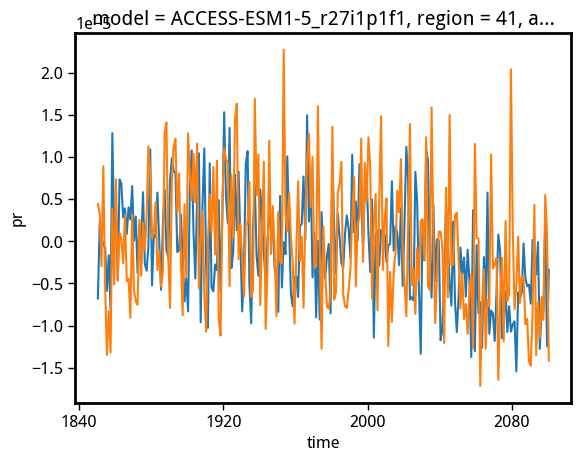

In [237]:
eaus_access_anom.isel(model=0).plot()
eaus_access_anom.isel(model=-1).plot()

In [238]:
eaus_access_det = funcs.detrend_separate_check(eaus_access_anom, dim='time', period=15)
eaus_access_std = eaus_access_det/eaus_access_det.std('time')

In [239]:
obs_regr_20c, obs_pval_20c = funcs.get_regr_1d(nino34_obs.sel(time=slice('1900', '2000')), eaus_std.sel(time=slice('1900', '2000'))), funcs.get_pval_1d(nino34_obs.sel(time=slice('1900', '2000')), eaus_std.sel(time=slice('1900', '2000')))

In [241]:
regr_20c_access = funcs.get_regr(nino34_access.sel(time=slice('1900', '2000')), eaus_access_std.sel(time=slice('1900', '2000')), dim='time')
pval_20c_access = funcs.get_pval(nino34_access.sel(time=slice('1900', '2000')), eaus_access_std.sel(time=slice('1900', '2000')), dim='time')

In [243]:
regr_21c_access = funcs.get_regr(nino34_access.sel(time=slice('2000', '2100')), eaus_access_std.sel(time=slice('2000', '2100')), dim='time')
pval_21c_access = funcs.get_pval(nino34_access.sel(time=slice('2000', '2100')), eaus_access_std.sel(time=slice('2000', '2100')), dim='time')

<AxesSubplot:ylabel='Count'>

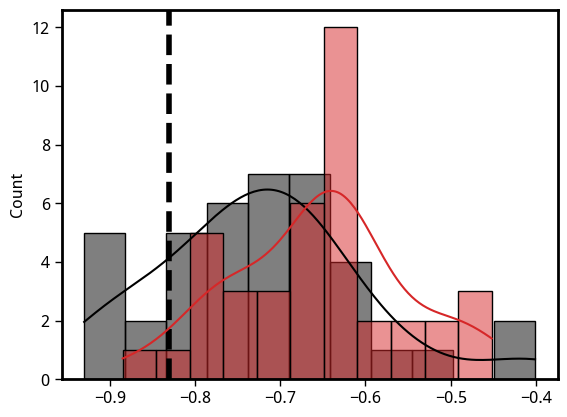

In [ ]:
plt.axvline(obs_regr_20c, color='k', ls='--', lw=4.0)
sns.histplot(regr_21c_access, bins=11, color='tab:red', alpha=0.5, kde=True)